In [40]:
import solarpy as sp
import pandas as pd
import numpy as np
from numpy import pi, exp, sqrt, sin, cos, tan, arccos
from datetime import datetime, timedelta

import matplotlib
from matplotlib import rc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)

In [41]:
### load datasets

# sun radiation spectral quantities from "Preetham et al. - A Practical Analytic Model for Daylight (Appendix A.6, Table 2)"
data0 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S0.txt')
data1 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S1.txt')
data2 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S2.txt')

lam = data0[:,0] # wavelength spectrum

S0  = data0[:,1] # scattering 0. sun radiation mean spectral radiant power (wavelength (nm, ?))
S1  = data1[:,1] # scattering 1
S2  = data2[:,1] # scattering 2

# photopic limunosity from www.cvrl.org, "CIE Photopic V(λ) modified by Judd (1951) and Vos (1978) [also known as CIE VM(λ)]", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
photopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/vljve.csv',skiprows=0,na_values = ['0'])
photopic_array = photopic.to_numpy()
photopic_V = photopic_array[:,1]

# scotopic limunosity from www.cvrl.org, "CIE (1951) Scotopic V'(λ)", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
scotopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/scvle.csv',skiprows=0,na_values = ['0'])
scotopic_array = scotopic.to_numpy()
scotopic_V = scotopic_array[:,1]

### City - Latitude Dictionaries

In [55]:
### matching cities with latitudes

latitude_city = {55.7: "Moscow",
                 52  : "Berlin",
                 51.5: "London",
                 41  : "Istanbul",
                 32.8: "Tripoli",
                 30  : "Cairo",
                 25  : "Sicily",
                -33.9: "Cape Town"}

### Irradiance on Earth

In [42]:
def irradiance_wavelength_distribution(date, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v   = phi_viewer*(pi/180)   # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    
    theta_s = sp.theta_z(date,latitude)
    phi_s = sp.solar_azimuth(date,latitude)
    
    gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
    
    Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
    Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
    
    theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
    
    xz = np.dot(T_vector,xz_matrix)
    xz = np.dot(xz, theta_s_vector)
    
    yz = np.dot(T_vector,yz_matrix)
    yz = np.dot(yz, theta_s_vector)
    
    
    FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
    FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
    
    Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
    Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
    
    Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
    Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
    
        
    Y = Yz*(FY_theta_gamma/FY_0_theta_s)
    x = xz*(Fx_theta_gamma/Fx_0_theta_s)
    y = yz*(Fy_theta_gamma/Fy_0_theta_s)
    
    M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
    M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
    
    SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
    
    for i in range(len(SD)):
        if SD[i] < 0:
            SD[i] = S0[i]
        else: pass
    
    scotopic_vision = SD*scotopic_V
    photopic_vision = SD*photopic_V
    
    
    return SD, scotopic_vision, photopic_vision, scotopic_vision+photopic_vision

In [43]:
### run - irradiance_on_earth

day = [datetime(2020,3,21, 5,0),
       datetime(2020,6,21, 5,0),
       datetime(2020,10,24, 0,0),
       datetime(2020,12,24, 0,0)]

lat = [25, 41, 52]

alt = 25
tur = 2

Theta_v = 80 # (zenith=0, horizon=90)
Phi_v   = 0 # (east=-90, south=0, west=90, north=180)

sd1, sc1, pc1, total1  = irradiance_wavelength_distribution(day[0],lat[0],alt,tur,Theta_v,Phi_v)

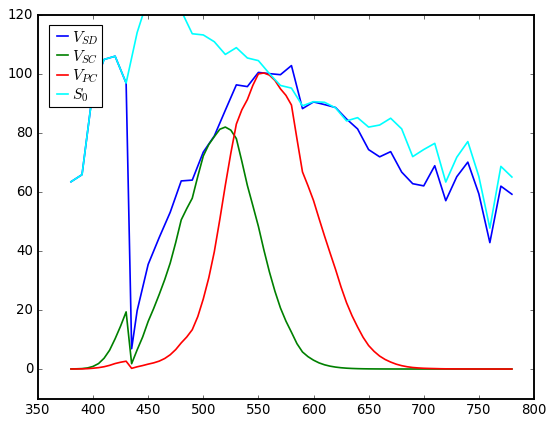

In [44]:
### plot - irradiance_on_earth

plt.style.use('classic')
linewidth = 1.7
sizeoffonts = 14
rc('lines', linewidth=1.5)
rc('axes', linewidth=linewidth)
rc('legend', labelspacing=0,
             handlelength=0,
             handletextpad=-0.1,
             columnspacing=-0.1,
             borderpad=0.1,
             borderaxespad=0.2,
             fontsize=sizeoffonts-2)

color = ['blue', 'green', 'red']

fig = plt.figure(figsize=(8,6), dpi=80)
fig.set_facecolor('none')

ax = plt.subplot(111)

ax.plot(lam, sd1,   label="$V_{SD}$", color=color[0])
ax.plot(lam, sc1, label="$V_{SC}$",    color=color[1])
ax.plot(lam, pc1, label="$V_{PC}$",    color=color[2])

ax.plot(lam, S0, label="$S_{0}$",    color='aqua')

ax.legend(loc='upper left',
         #bbox_to_anchor=(0.31, 0.7),
          prop={'size':sizeoffonts},
         #title="$\mathrm{T/T_c}$",
          labelspacing=.1,
          handlelength=1.3,
          handletextpad=0.,
          borderpad=0.2,
          borderaxespad=0.7)

ax.set_xlim(350, 800)
ax.set_ylim(-10, 120)
#ax.xaxis.set_ticks([350, 450, 550, 650, 750])
#ax.yaxis.set_ticks([0, 50, 100, 150, 200])
#ax.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

#ax.text(360,166, str(day[3].day)+"."+str(day[3].month)+"."+str(day[3].year), fontsize=sizeoffonts)

plt.show()

#fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/RadiantPower_Wavelength/RadiantPower_Wavelength_Phi"+str(Phi_v)+".png", format='png', bbox_inches='tight')

### Irradiance During A Day

In [80]:
def irradiance_during_a_day(date, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v   = phi_viewer*(pi/180)   # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    vision_sd = []
    
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date+timedelta(minutes=m),latitude)
        phi_s = sp.solar_azimuth(date+timedelta(minutes=m),latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        for i in range(len(SD)):
            if SD[i] < 0:
                SD[i] = 0
            else: pass
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        vision_sd.append(sum(SD))
        vision.append((sum(scotopic_vision)+sum(photopic_vision)))
        
    #time_scale = [i/60 for i in range(0,1440,10)]
    time_scale = [date+timedelta(minutes=i) for i in range(0, 6*10*24, 10)]
    
    return time_scale, vision_sd, vision

In [81]:
### run - irradiance_during_a_day

day = datetime(2020,3,21)

lat = 41
alt = 25
tur = 2

Theta_v = 80 # (zenith=0, horizon=90)
Phi_v   = 0 # (east=-90, south=0, west=90, north=180)

t, sd, v  = irradiance_during_a_day(day,lat,alt,tur,Theta_v,Phi_v)

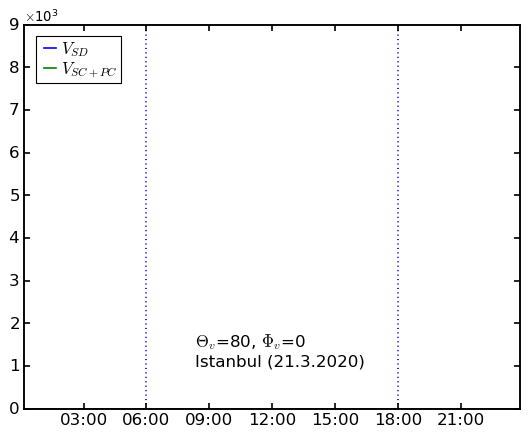

In [82]:
### plot - irradiance_during_a_day

plt.style.use('classic')
linewidth = 1.7
sizeoffonts = 15
rc('lines', linewidth=1.5)
rc('axes', linewidth=linewidth)
rc('legend', labelspacing=0,
             handlelength=0,
             handletextpad=-0.1,
             columnspacing=-0.1,
             borderpad=0.1,
             borderaxespad=0.2,
             fontsize=sizeoffonts-2)

color = ['blue', 'green', 'red']

fig = plt.figure(figsize=(8,6), dpi=80)
fig.set_facecolor('none')
#fig.text(0.0, 0.5, "$\mathrm{Spectral}$ $\mathrm{Radiant}$ $\mathrm{Power}$ $\mathrm{Density}$ $\mathrm{(W/m^2)}$", va='center', rotation='vertical', fontsize=sizeoffonts+5)
#fig.text(0.5, 0.05, "$\mathrm{Hour}$", ha='center', fontsize=sizeoffonts+5)


ax = plt.subplot(111)
ax.plot(t, sd,   label="$V_{SD}$", color=color[0])
ax.plot(t, v, label="$V_{SC+PC}$",    color=color[1])

myFmt = mdates.DateFormatter('%H:%M')
ax.xaxis.set_major_formatter(myFmt)

ax.set_xlim(t[1], t[-1])
ax.set_ylim(0, 9e3)
plt.ticklabel_format(axis='y', style="sci", useMathText=True, useOffset=True, useLocale=False, scilimits=(0,0))
ax.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax.legend(loc='upper left',
         #bbox_to_anchor=(0.31, 0.7),
          prop={'size':sizeoffonts},
         #title="$\mathrm{T/T_c}$",
          labelspacing=.1,
          handlelength=1.3,
          handletextpad=0.,
          borderpad=0.2,
          borderaxespad=0.7)

ax.text(t[50],1000, "$\Theta_v$="+str(np.round(Theta_v,3))+", $\Phi_v$="+str(np.round(Phi_v,3))+
        "\n"+latitude_city[lat]+" ("+str(day.day)+"."+str(day.month)+"."+str(day.year)+")", fontsize=sizeoffonts)

plt.axvline(sp.sunrise_time(day,lat), ls=':')
plt.axvline(sp.sunset_time(day,lat),  ls=':')
#plt.axhline(0, ls='--')


plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

#fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/RadiantPower_Hour_Phi"+str(Phi_v)+".png", format='png', bbox_inches='tight')